In [1]:
import torch
from torchvision import transforms
import torch.optim as optim
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv

In [2]:
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


## ResNet standard per Cifar10

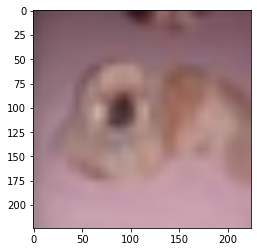

In [30]:
# show images
imshow(torchvision.utils.make_grid(inputs))
# print labels


torch.Size([2048, 7, 7])


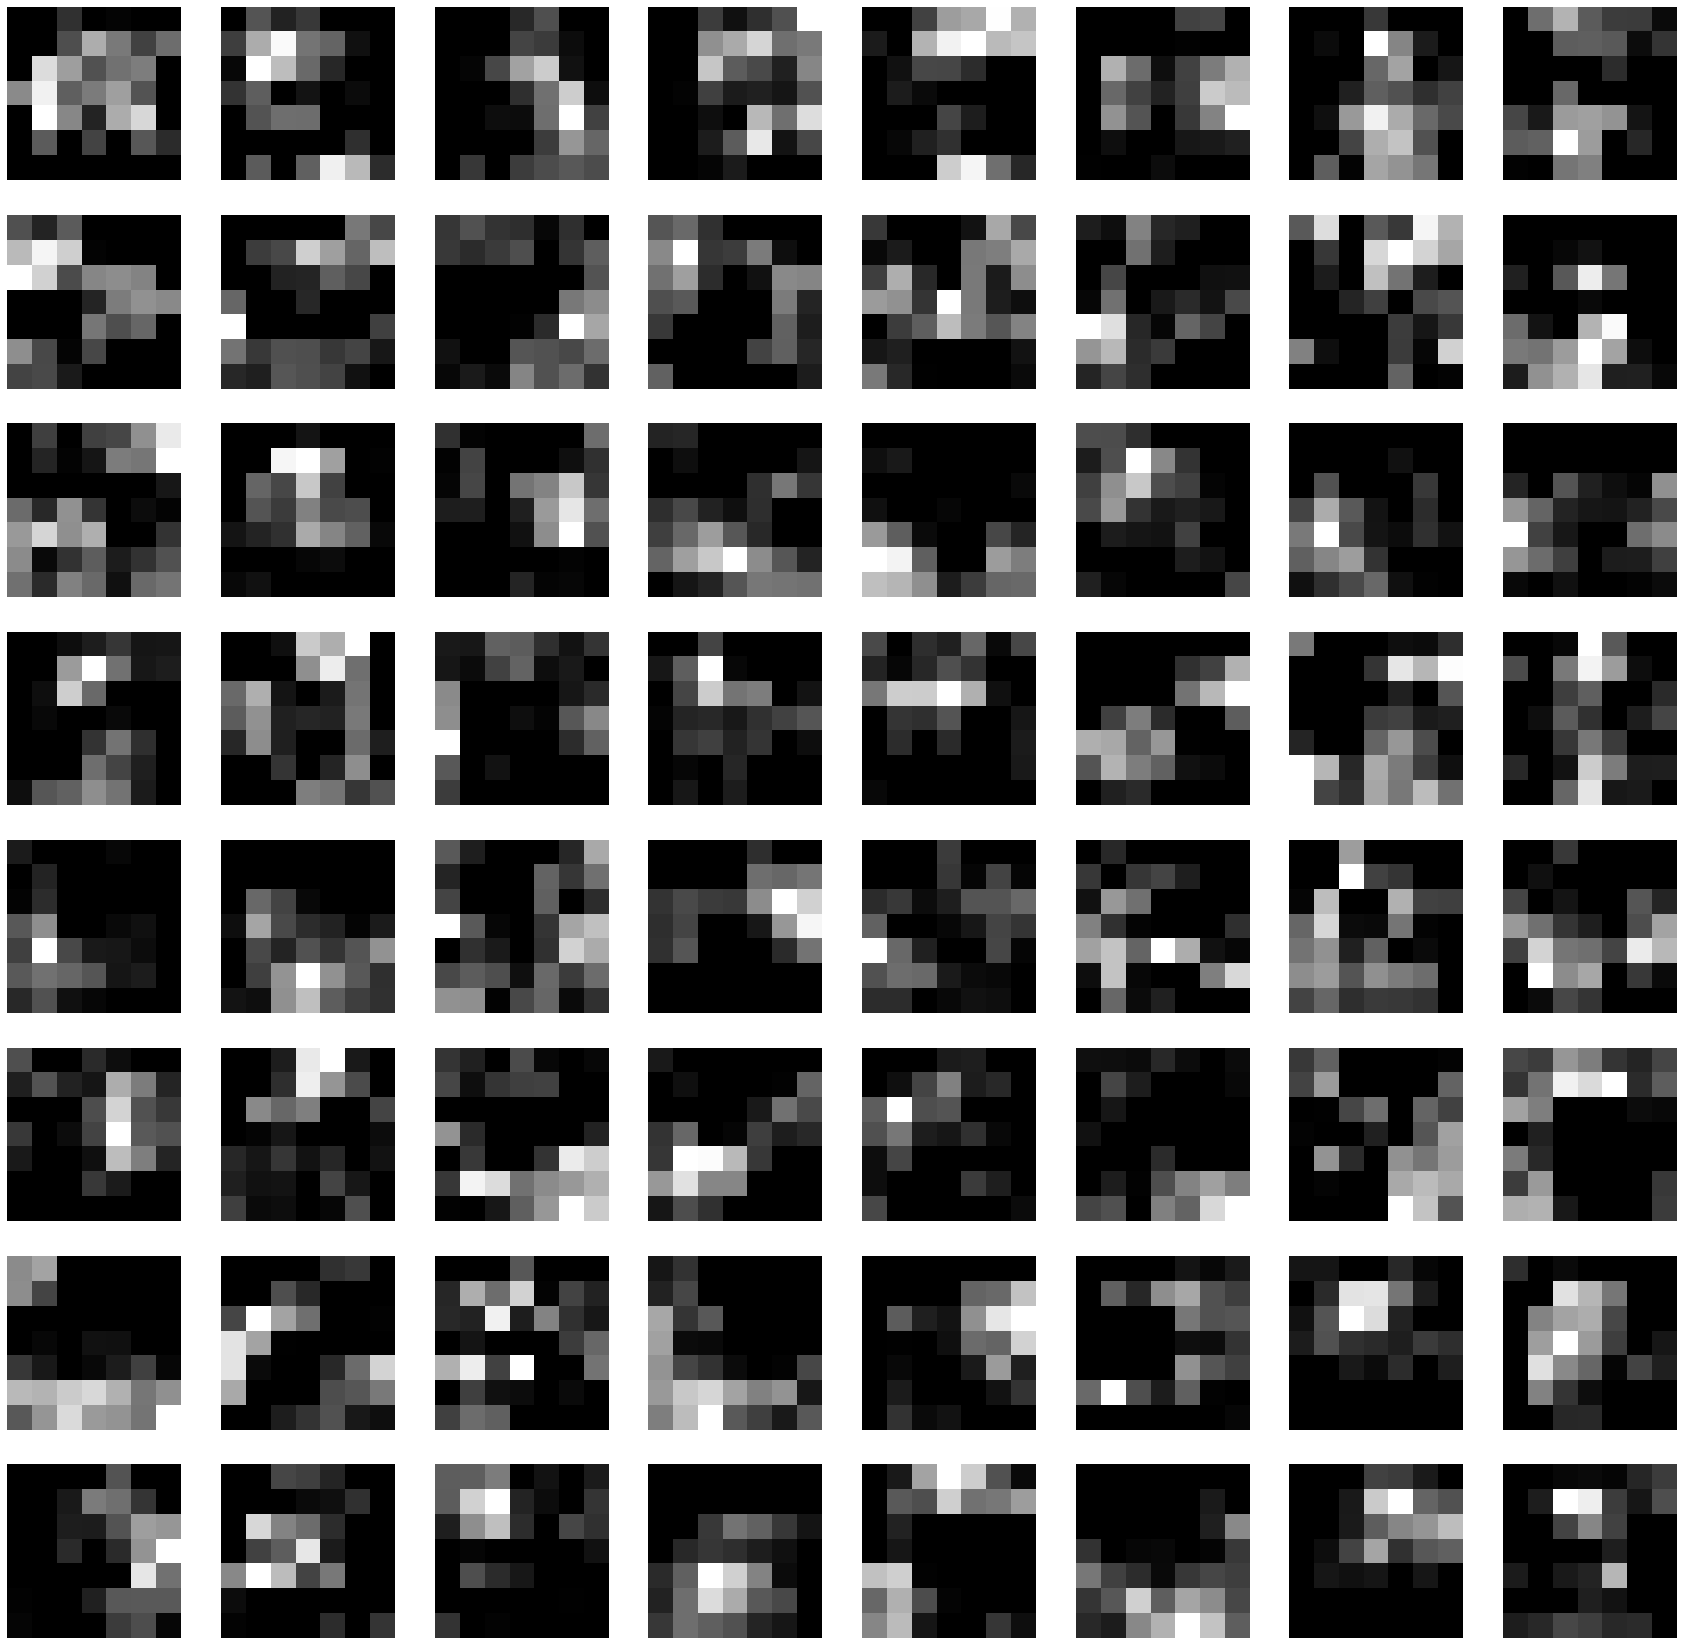

In [33]:
plt.figure(figsize=(30, 30))
layer_viz = output[0, :, :, :]
layer_viz = layer_viz.data
print(layer_viz.size())
for i, filter in enumerate(layer_viz):
    if i == 64: # we will visualize only 8x8 blocks from each layer
        break
    plt.subplot(8, 8, i + 1)
    plt.imshow(filter, cmap='gray')
    plt.axis("off")
plt.show()
plt.close()

In [6]:
new_cifar_model = torch.torch.torch.nn.Sequential(*(list(model.children())[:-2]))

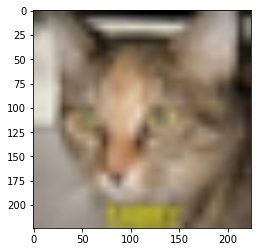

In [16]:
imshow(torchvision.utils.make_grid(inputs))

In [ ]:
plt.figure(figsize=(30, 30))
layer_viz = output[0, :, :, :]
layer_viz = layer_viz.data
print(layer_viz.size())
for i, filter in enumerate(layer_viz):
    if i == 64: # we will visualize only 8x8 blocks from each layer
        break
    plt.subplot(8, 8, i + 1)
    plt.imshow(filter, cmap='gray')
    plt.axis("off")
plt.show()
plt.close()

In [3]:
import torch
from torchvision import transforms
import torch.optim as optim
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import pytorch_lightning as pl
from Models import resnetModule, resnet_cifar10
import seaborn as sns

In [9]:
transform = transforms.Compose([
    # transforms.Pad(4),
    # transforms.RandomCrop(34),
    # transforms.RandomHorizontalFlip(),
    transforms.ToTensor()])

batch_size = 1

dataset = torchvision.datasets.CIFAR10('./datasets/data',train=True, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size,
                                          shuffle=False, num_workers=2)


Files already downloaded and verified


torch.Size([1, 3, 32, 32])


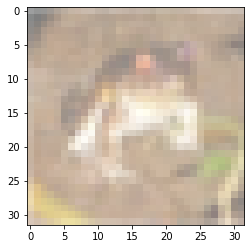

In [10]:
# load image
image, _ = next(iter(trainloader))
print(image.shape)
# show images
imshow(torchvision.utils.make_grid(image))
# print labels

In [42]:
model = resnetModule.ResNetModule.load_from_checkpoint('/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnetOfficial_SGD_WD_REL/checkpoints/best-v1.ckpt')
# model = torch.nn.Sequential(
#     model,
#     model.class_layer
# )
model = resnetModule.ResNetModule.load_from_checkpoint('/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnetOfficial_SGD_WD_REL_ONLY/checkpoints/best.ckpt')
# model = resnetModule.ResNetModule.load_from_checkpoint('/Users/lucamelissari/Desktop/MasterThesis/jobs/stats/resnetOfficialNet_SGD_WD/checkpoints/best.ckpt')

trainer = pl.Trainer()

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


take cifar 10 official model 
 stampo calss layer <bound method Module.state_dict of Sequential(
  (0): Final_layers()
  (1): Linear(in_features=64, out_features=10, bias=True)
)>


In [28]:
len(list(list(model.children())[0].children())[0])

5

Total convolution layers: 55
conv_layers
55


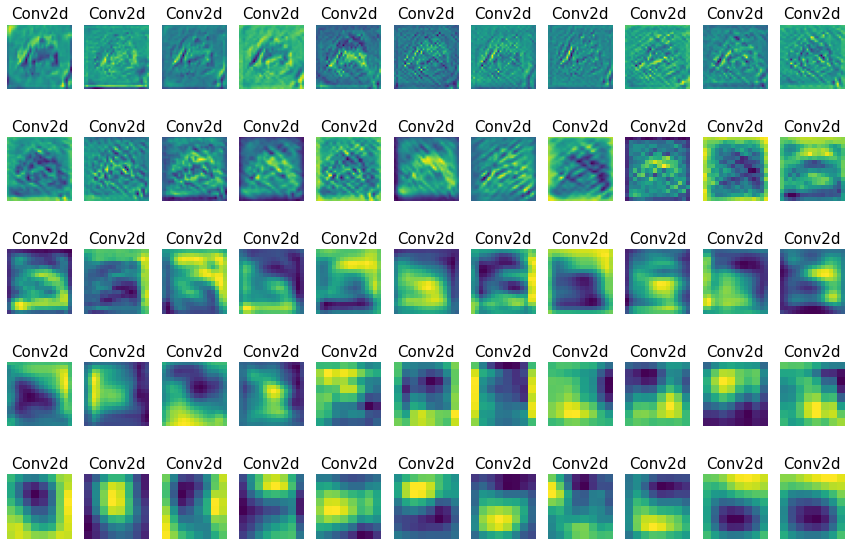

In [50]:
## GET CONV LAYER FROM MODEL 
# we will save the conv layer weights in this list
model_weights =[]
#we will save the 49 conv layers in this list
conv_layers = []
# get all the model children as list
model_children = list(list(model.children())[0].children())[0] # baseline model 

#counter to keep count of the conv layers
counter = 0
#append all the conv layers and their respective wights to the list
for i in range(len(model_children)):    
    if type(model_children[i]) == torch.nn.Conv2d:
        counter+=1
        model_weights.append(model_children[i].weight)
        conv_layers.append(model_children[i])
    elif type(model_children[i]) == torch.nn.Sequential:
        for j in range(len(model_children[i])):
            for child in model_children[i][j].children():
                if type(child) == torch.nn.Conv2d:
                    counter+=1
                    model_weights.append(child.weight)
                    conv_layers.append(child)
print(f"Total convolution layers: {counter}")
print("conv_layers")
last_conv = conv_layers[-1]
outputs = []
names = []
image_to_process = image
for layer in conv_layers[0:]:
    image_to_process = layer(image_to_process)
    outputs.append(image_to_process)
    names.append(str(layer))
print(len(outputs))
processed = []
for feature_map in outputs:
    feature_map = feature_map.squeeze(0)
    gray_scale = torch.sum(feature_map,0)
    gray_scale = gray_scale / feature_map.shape[0]
    processed.append(gray_scale.data.cpu().numpy())

fig = plt.figure(figsize=(15, 10))
for i in range(len(processed)):
    a = fig.add_subplot(5, 11, i+1)
    imgplot = plt.imshow(processed[i])
    a.axis("off")
    a.set_title(names[i].split('(')[0], fontsize=15)
plt.savefig(str('feature_maps_frog_upstream.jpg'), bbox_inches='tight') # ONLY FOR SAVE THE IMAGE

In [49]:
model.eval()
pred = model(image).argmax(dim=1)
print(pred)
print(_)

tensor([6])
(<Figure size 576x432 with 4 Axes>, array([<AxesSubplot:>, <AxesSubplot:>], dtype=object))


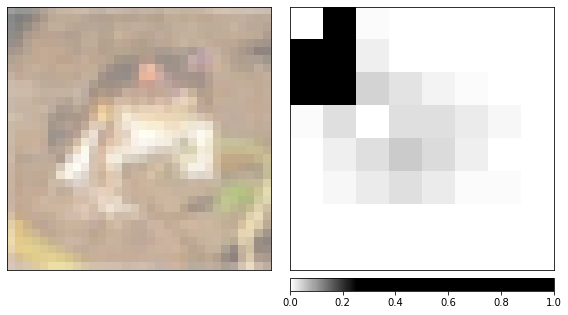

In [47]:
from captum.attr import LayerGradCam
from captum.attr import LayerAttribution
from matplotlib.colors import LinearSegmentedColormap
from captum.attr import visualization as viz

default_cmap = LinearSegmentedColormap.from_list('custom blue', 
                                                 [(0, '#ffffff'),
                                                  (0.25, '#000000'),
                                                  (1, '#000000')], N=256)

layer_gc = LayerGradCam(model, last_conv)
printer_image = np.transpose((image.squeeze().cpu().detach().numpy() / 2) + 0.5, (1, 2, 0))
attribution = layer_gc.attribute(image,6)
upsampled_attr = LayerAttribution.interpolate(attribution, (32, 32))
printer_attr = np.transpose(upsampled_attr.squeeze(0).cpu().detach().numpy(), (1,2,0))
_ = viz.visualize_image_attr_multiple(
    printer_attr, 
    printer_image,
    ["original_image", "heat_map"],
    ["all", "positive"], 
    cmap=default_cmap, 
    show_colorbar=True,
    outlier_perc=1
    )

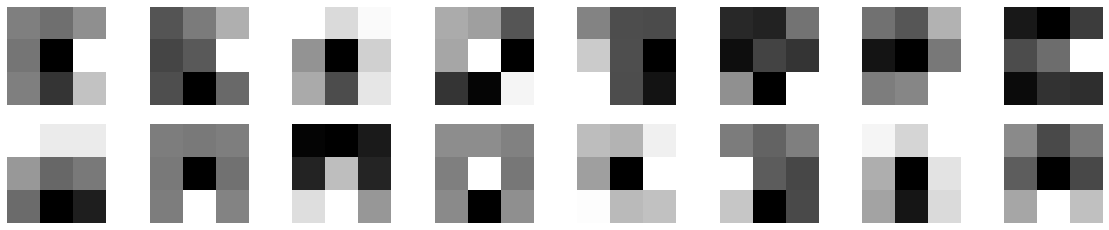

In [34]:
# visualize the first conv layer filters
plt.figure(figsize=(20, 17))
for i, filter in enumerate(model_weights[0]):
    plt.subplot(8, 8, i+1) # (8, 8) because in conv0 we have 7x7 filters and total of 64 (see printed shapes)
    plt.imshow(filter[0, :, :].detach(), cmap='gray')
    plt.axis('off')
plt.show()